## **Import Libraries**

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Load **Dataset**

In [17]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  


# **Explore Data**

In [18]:
# Display dataset shape
print("Dataset Shape:")
print(df.shape)

# Display columns
print("\nDataset Columns:")
print(df.columns)

# Display information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Count each species
print("\nSpecies Counts:")
print(df["species"].value_counts())

Dataset Shape:
(150, 5)

Dataset Columns:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          

# **Data Visualization**

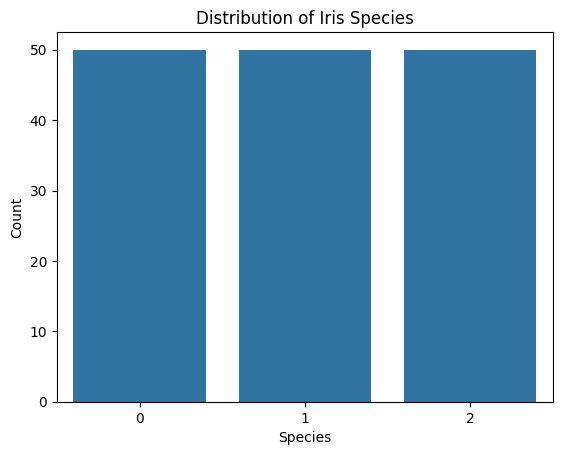

In [19]:
# Species distribution
sns.countplot(x="species", data=df)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

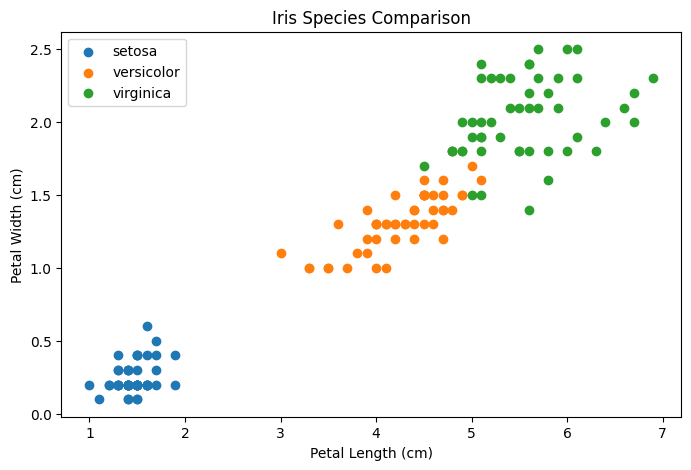

In [20]:
# Compare flower species
plt.figure(figsize=(8, 5))

for species in df["species"].unique():

    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=iris.target_names[species]
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Species Comparison")
plt.legend()
plt.show()

# **Prepare Data**

In [21]:
# Features
X = df.drop("species", axis=1)

# Target
y = df["species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


# **Build KNN Model**

In [22]:
knn = KNeighborsClassifier(n_neighbors=3)

# Train model
knn.fit(X_train, y_train)

# Make predictions
y_pred = knn.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison)

    Actual  Predicted
0        0          0
1        2          2
2        1          1
3        1          1
4        0          0
5        1          1
6        0          0
7        0          0
8        2          2
9        1          1
10       2          2
11       2          2
12       2          2
13       1          1
14       0          0
15       0          0
16       0          0
17       1          1
18       1          1
19       2          2
20       0          0
21       2          2
22       1          1
23       2          2
24       2          2
25       1          1
26       1          1
27       0          0
28       2          2
29       0          0


# **Evaluate Original Model**

In [23]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


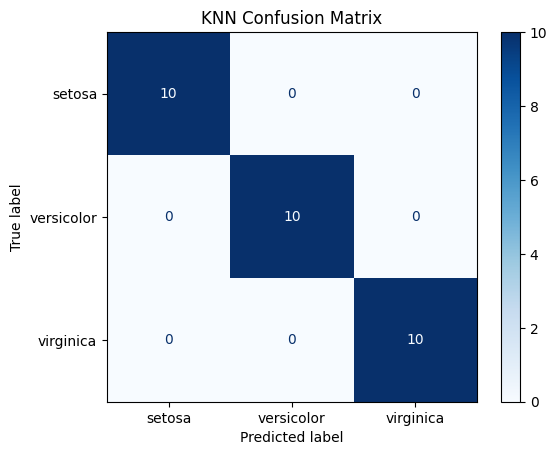

In [24]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

In [25]:
# Classification Report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# **Feature Scaling**

In [26]:
scaled_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

# Train scaled model
scaled_knn.fit(X_train, y_train)

# Predictions
scaled_predictions = scaled_knn.predict(X_test)

# Calculate accuracy
scaled_accuracy = accuracy_score(
    y_test,
    scaled_predictions
)

print("Accuracy after scaling:", scaled_accuracy * 100, "%")

Accuracy after scaling: 93.33333333333333 %


# **Compare Models**

In [27]:
results = pd.DataFrame({
    "Model": ["Original KNN", "Scaled KNN"],
    "Accuracy": [
        accuracy * 100,
        scaled_accuracy * 100
    ]
})

print(results)

          Model    Accuracy
0  Original KNN  100.000000
1    Scaled KNN   93.333333


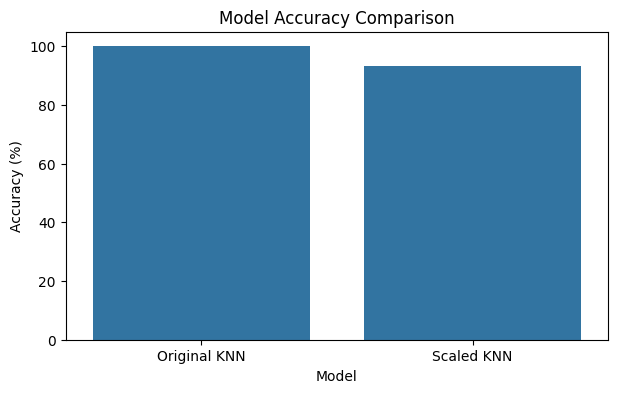

In [28]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

# **Test New Flower**

In [29]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = scaled_knn.predict(new_flower)

predicted_species = iris.target_names[prediction[0]]

print("Predicted Flower Species:", predicted_species)

Predicted Flower Species: setosa


# **Conclusion**

In this project, we used the Iris dataset to classify flowers into three species: Setosa, Versicolor, and Virginica.

We explored and analyzed the dataset using Pandas and created visualizations using Matplotlib and Seaborn.

We trained a K-Nearest Neighbors (KNN) classification model and evaluated its performance using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.

We also applied Feature Scaling using StandardScaler to improve the model's distance calculations and compared the original and scaled models.

Finally, we tested the model using a new flower sample to predict its species.